# Model Training — Speech Emotion Recognition (SER)
Notebook ini melatih model hybrid CNN-BiLSTM-Transformer secara terpisah untuk data **male** dan **female**.
Semua kode berjalan langsung (inline), tidak ada fungsi atau class yang perlu dipanggil secara terpisah.

## 1. Import Library & Konfigurasi Global

In [2]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D, BatchNormalization,
    Bidirectional, LSTM, Dense, Dropout, LayerNormalization,
    GlobalAveragePooling1D, MultiHeadAttention, Add
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    ModelCheckpoint, ReduceLROnPlateau
)
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
import seaborn as sns

# ─────────────────────────────────────────────
# KONFIGURASI UTAMA — ubah sesuai kebutuhan
# ─────────────────────────────────────────────
DATA_DIR     = '/kaggle/input/datasets/syahrulkalzayyan/datagabungan/extracted_features'   # Arahkan ke folder hasil feature_extraction
RANDOM_STATE = 42
BATCH_SIZE   = 32
EPOCHS       = 50

sns.set_style('whitegrid')
print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.19.0


---
## 2. Pelatihan Model MALE
### 2a. Load Data Male

In [3]:
GENDER       = 'male'
gender_folder = os.path.join(DATA_DIR, GENDER)

print(f"\n{'='*50}")
print(f'PROSES PELATIHAN MODEL {GENDER.upper()}')
print(f"{'='*50}")

# ── Load semua file .npz ─────────────────────────────────────────────────────
all_features, all_labels = [], []
for file_name in os.listdir(gender_folder):
    if file_name.endswith('.npz'):
        file_path = os.path.join(gender_folder, file_name)
        data = np.load(file_path)
        if 'features' not in data or 'labels' not in data:
            raise ValueError(f'File {file_name} tidak memiliki key features/labels')
        all_features.append(data['features'])
        all_labels.append(data['labels'])
        print(f'[{GENDER}] Loaded {file_name}: {data["features"].shape}, {data["labels"].shape}')

if not all_features:
    raise ValueError(f'Tidak ada file .npz valid di {gender_folder}')

X_male = np.concatenate(all_features, axis=0)
y_male = np.concatenate(all_labels, axis=0)

print(f'\nData {GENDER} awal:')
print(f'  Features shape : {X_male.shape}')
print(f'  Labels shape   : {y_male.shape}')
print(f'  Distribusi kelas: {np.bincount(y_male)}')


PROSES PELATIHAN MODEL MALE
[male] Loaded SAVEE_features.npz: (1200, 128, 121), (1200,)
[male] Loaded RAVDESS_features.npz: (960, 128, 121), (960,)
[male] Loaded IndoWaveSentiment_features.npz: (200, 128, 121), (200,)
[male] Loaded E-SERAVD_features.npz: (500, 128, 121), (500,)
[male] Loaded CREMA-D_features.npz: (6710, 128, 121), (6710,)

Data male awal:
  Features shape : (9570, 128, 121)
  Labels shape   : (9570,)
  Distribusi kelas: [1529 1529 2029 1479 1477 1527]


### 2b. Preprocessing & Split Data Male

In [4]:
num_classes_male = len(np.unique(y_male))
print(f'Jumlah kelas emosi untuk {GENDER}: {num_classes_male}')

# Normalisasi
mean_male = X_male.mean(axis=(0, 1), keepdims=True)
std_male  = X_male.std(axis=(0, 1), keepdims=True) + 1e-8
X_male    = (X_male - mean_male) / std_male
print(f'Data {GENDER} dinormalisasi')

# Train / test split (85% : 15%)
X_train_m, X_test_m, y_train_int_m, y_test_int_m = train_test_split(
    X_male, y_male, test_size=0.15, random_state=RANDOM_STATE, stratify=y_male
)
# Train / val split (~85% : 15% of train => ~72.25% : 12.75%)
X_train_m, X_val_m, y_train_int_m, y_val_int_m = train_test_split(
    X_train_m, y_train_int_m, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_train_int_m
)

# One-hot encoding
y_train_m = to_categorical(y_train_int_m, num_classes=num_classes_male)
y_val_m   = to_categorical(y_val_int_m,   num_classes=num_classes_male)
y_test_m  = to_categorical(y_test_int_m,  num_classes=num_classes_male)

print(f'\nSplit {GENDER} final:')
print(f'  Train      : {X_train_m.shape}, {y_train_m.shape}')
print(f'  Validation : {X_val_m.shape}, {y_val_m.shape}')
print(f'  Test       : {X_test_m.shape}, {y_test_m.shape}')

# Class weights
class_weights_male = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train_int_m),
    y=y_train_int_m
)
class_weights_male = dict(enumerate(class_weights_male))
print(f'\nClass weights untuk {GENDER}:')
for cls, w in class_weights_male.items():
    print(f'  Kelas {cls}: {w:.4f}')

Jumlah kelas emosi untuk male: 6
Data male dinormalisasi

Split male final:
  Train      : (6698, 128, 121), (6698, 6)
  Validation : (1436, 128, 121), (1436, 6)
  Test       : (1436, 128, 121), (1436, 6)

Class weights untuk male:
  Kelas 0: 1.0433
  Kelas 1: 1.0423
  Kelas 2: 0.7862
  Kelas 3: 1.0786
  Kelas 4: 1.0807
  Kelas 5: 1.0443


### 2c. Bangun Model Male

In [5]:
model_name_m = 'male_model'
input_shape_m = X_train_m.shape[1:]

inputs_m = Input(shape=input_shape_m, name=f'{model_name_m}_input')

# CNN Block
x_m = Conv1D(64, kernel_size=3, padding='same', activation='relu', name=f'{model_name_m}_conv1')(inputs_m)
x_m = BatchNormalization(name=f'{model_name_m}_bn1')(x_m)
x_m = MaxPooling1D(pool_size=2, name=f'{model_name_m}_mp1')(x_m)
x_m = Dropout(0.3, name=f'{model_name_m}_drop1')(x_m)

x_m = Conv1D(128, kernel_size=3, padding='same', activation='relu', name=f'{model_name_m}_conv2')(x_m)
x_m = BatchNormalization(name=f'{model_name_m}_bn2')(x_m)
x_m = MaxPooling1D(pool_size=2, name=f'{model_name_m}_mp2')(x_m)
x_m = Dropout(0.3, name=f'{model_name_m}_drop2')(x_m)

# BiLSTM Block
x_m = Bidirectional(LSTM(128, return_sequences=True, name=f'{model_name_m}_lstm'), name=f'{model_name_m}_bilstm')(x_m)
x_m = Dropout(0.4, name=f'{model_name_m}_drop3')(x_m)

# Transformer Block
attention_m = MultiHeadAttention(num_heads=4, key_dim=64, name=f'{model_name_m}_mha')(x_m, x_m)
attention_m = Dropout(0.3, name=f'{model_name_m}_drop4')(attention_m)
x_m = Add(name=f'{model_name_m}_residual')([x_m, attention_m])
x_m = LayerNormalization(name=f'{model_name_m}_ln')(x_m)

# Klasifikasi
x_m = GlobalAveragePooling1D(name=f'{model_name_m}_gap')(x_m)
x_m = Dense(128, activation='relu', name=f'{model_name_m}_dense1')(x_m)
x_m = Dropout(0.5, name=f'{model_name_m}_drop5')(x_m)
outputs_m = Dense(num_classes_male, activation='softmax', name=f'{model_name_m}_output')(x_m)

model_male = Model(inputs=inputs_m, outputs=outputs_m, name=model_name_m)
model_male.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f'\nArsitektur model {GENDER}:')
model_male.summary()

I0000 00:00:1774277435.478885      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774277435.484692      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



Arsitektur model male:


Model: "male_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ male_model_input    │ (None, 128, 121)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_conv1    │ (None, 128, 64)   │     23,296 │ male_model_input… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_bn1      │ (None, 128, 64)   │        256 │ male_model_conv1… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_mp1      │ (None, 64, 64)    │          0 │ male_model_bn1[0… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_drop1    │ (None, 64, 64)    │          0 │ male_model_mp1[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_conv2    │ (None, 64, 128)   │     24,704 │ male_model_drop1… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_bn2      │ (None, 64, 128)   │        512 │ male_model_conv2… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_mp2      │ (None, 32, 128)   │          0 │ male_model_bn2[0… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_drop2    │ (None, 32, 128)   │          0 │ male_model_mp2[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_bilstm   │ (None, 32, 256)   │    263,168 │ male_model_drop2… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_drop3    │ (None, 32, 256)   │          0 │ male_model_bilst… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_mha      │ (None, 32, 256)   │    263,168 │ male_model_drop3… │
│ (MultiHeadAttentio… │                   │            │ male_model_drop3… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_drop4    │ (None, 32, 256)   │          0 │ male_model_mha[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_residual │ (None, 32, 256)   │          0 │ male_model_drop3… │
│ (Add)               │                   │            │ male_model_drop4… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_ln       │ (None, 32, 256)   │        512 │ male_model_resid… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_gap      │ (None, 256)       │          0 │ male_model_ln[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ male_model_dense1   │ (None, 128)       │     32,896 │ male_model_gap[0

 Total params: 609,286 (2.32 MB)

 Trainable params: 608,902 (2.32 MB)

 Non-trainable params: 384 (1.50 KB)

### 2d. Training Model Male

In [6]:
callbacks_male = [
    ModelCheckpoint(
        f'best_{GENDER}_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        verbose=1
    )
]

print(f'\nMemulai pelatihan model {GENDER}...')
history_male = model_male.fit(
    X_train_m, y_train_m,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val_m, y_val_m),
    class_weight=class_weights_male,
    callbacks=callbacks_male,
    verbose=1
)


Memulai pelatihan model male...
Epoch 1/50


I0000 00:00:1774277443.126011     127 cuda_dnn.cc:529] Loaded cuDNN version 91002


210/210 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2998 - loss: 1.6880
Epoch 1: val_accuracy improved from -inf to 0.40669, saving model to best_male_model.keras
210/210 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.3001 - loss: 1.6875 - val_accuracy: 0.4067 - val_loss: 1.5456 - learning_rate: 0.0010
Epoch 2/50
209/210 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4324 - loss: 1.4271
Epoch 2: val_accuracy improved from 0.40669 to 0.52646, saving model to best_male_model.keras
210/210 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.4326 - loss: 1.4268 - val_accuracy: 0.5265 - val_loss: 1.2406 - learning_rate: 0.0010
Epoch 3/50
209/210 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5229 - loss: 1.2413
Epoch 3: val_accuracy improved from 0.52646 to 0.56337, saving model to best_male_model.keras
210/210 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.5230 - loss: 1.2412 - val_accuracy: 0.5634 - val_loss: 1.1571 - learning_rate: 0.0010
Epoch 4/50
208/210 ━━━━━━━━━━━━━━━━━━━━ 0s 1

### 2e. Evaluasi & Simpan Model Male


Evaluasi model male pada data test:
  Test Loss    : 1.2631
  Test Accuracy: 0.7967
Model male disimpan sebagai 'final_male_model.keras'
Grafik training disimpan sebagai 'male_training_history.png'


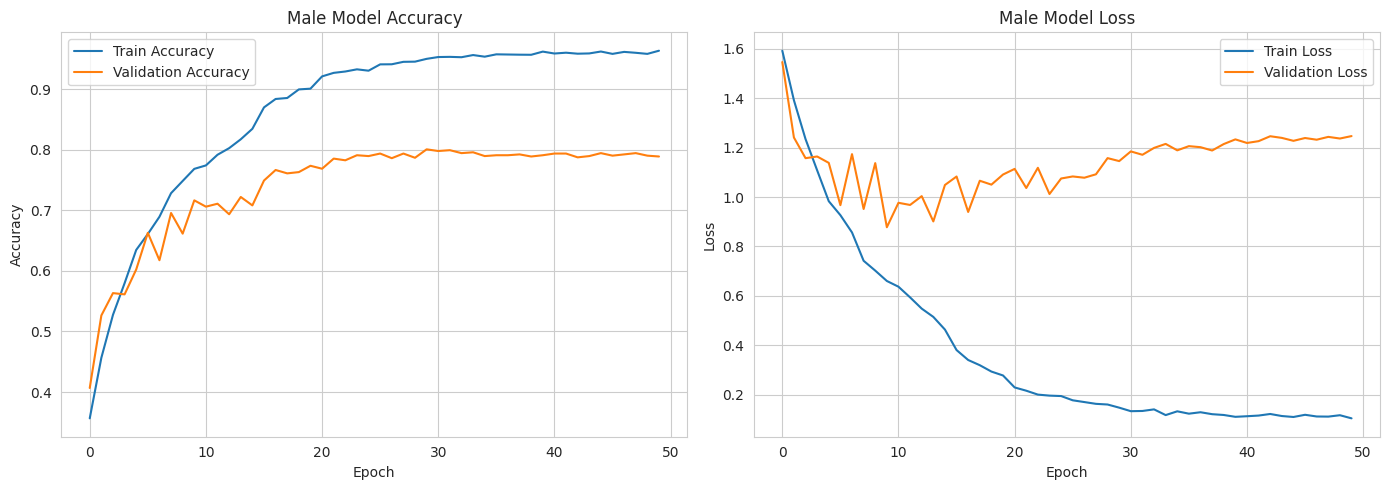

History male tersimpan.


In [7]:
print(f'\nEvaluasi model {GENDER} pada data test:')
test_loss_m, test_acc_m = model_male.evaluate(X_test_m, y_test_m, verbose=0)
print(f'  Test Loss    : {test_loss_m:.4f}')
print(f'  Test Accuracy: {test_acc_m:.4f}')

model_male.save(f'final_{GENDER}_model.keras')
print(f"Model {GENDER} disimpan sebagai 'final_{GENDER}_model.keras'")

# ── Plot training history ──────────────────────────────────────────────────
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_male.history['accuracy'],     label='Train Accuracy')
plt.plot(history_male.history['val_accuracy'], label='Validation Accuracy')
plt.title(f'{GENDER.capitalize()} Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_male.history['loss'],     label='Train Loss')
plt.plot(history_male.history['val_loss'], label='Validation Loss')
plt.title(f'{GENDER.capitalize()} Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.savefig(f'{GENDER}_training_history.png')
print(f"Grafik training disimpan sebagai '{GENDER}_training_history.png'")
plt.show()

# Simpan history
np.save(f'{GENDER}_training_history.npy', history_male.history)
print(f'History {GENDER} tersimpan.')

---
## 3. Pelatihan Model FEMALE
### 3a. Load Data Female

In [8]:
GENDER        = 'female'
gender_folder = os.path.join(DATA_DIR, GENDER)

print(f"\n{'='*50}")
print(f'PROSES PELATIHAN MODEL {GENDER.upper()}')
print(f"{'='*50}")

all_features, all_labels = [], []
for file_name in os.listdir(gender_folder):
    if file_name.endswith('.npz'):
        file_path = os.path.join(gender_folder, file_name)
        data = np.load(file_path)
        if 'features' not in data or 'labels' not in data:
            raise ValueError(f'File {file_name} tidak memiliki key features/labels')
        all_features.append(data['features'])
        all_labels.append(data['labels'])
        print(f'[{GENDER}] Loaded {file_name}: {data["features"].shape}, {data["labels"].shape}')

if not all_features:
    raise ValueError(f'Tidak ada file .npz valid di {gender_folder}')

X_female = np.concatenate(all_features, axis=0)
y_female = np.concatenate(all_labels, axis=0)

print(f'\nData {GENDER} awal:')
print(f'  Features shape : {X_female.shape}')
print(f'  Labels shape   : {y_female.shape}')
print(f'  Distribusi kelas: {np.bincount(y_female)}')


PROSES PELATIHAN MODEL FEMALE
[female] Loaded RAVDESS_features.npz: (960, 128, 121), (960,)
[female] Loaded IndoWaveSentiment_features.npz: (200, 128, 121), (200,)
[female] Loaded TESS_features.npz: (4000, 128, 121), (4000,)
[female] Loaded E-SERAVD_features.npz: (500, 128, 121), (500,)
[female] Loaded CREMA-D_features.npz: (6000, 128, 121), (6000,)

Data female awal:
  Features shape : (11660, 128, 121)
  Labels shape   : (11660,)
  Distribusi kelas: [1862 2382 1862 1834 1834 1886]


### 3b. Preprocessing & Split Data Female

In [9]:
num_classes_female = len(np.unique(y_female))
print(f'Jumlah kelas emosi untuk {GENDER}: {num_classes_female}')

# Normalisasi
mean_female = X_female.mean(axis=(0, 1), keepdims=True)
std_female  = X_female.std(axis=(0, 1), keepdims=True) + 1e-8
X_female    = (X_female - mean_female) / std_female
print(f'Data {GENDER} dinormalisasi')

X_train_f, X_test_f, y_train_int_f, y_test_int_f = train_test_split(
    X_female, y_female, test_size=0.15, random_state=RANDOM_STATE, stratify=y_female
)
X_train_f, X_val_f, y_train_int_f, y_val_int_f = train_test_split(
    X_train_f, y_train_int_f, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_train_int_f
)

y_train_f = to_categorical(y_train_int_f, num_classes=num_classes_female)
y_val_f   = to_categorical(y_val_int_f,   num_classes=num_classes_female)
y_test_f  = to_categorical(y_test_int_f,  num_classes=num_classes_female)

print(f'\nSplit {GENDER} final:')
print(f'  Train      : {X_train_f.shape}, {y_train_f.shape}')
print(f'  Validation : {X_val_f.shape}, {y_val_f.shape}')
print(f'  Test       : {X_test_f.shape}, {y_test_f.shape}')

class_weights_female = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_train_int_f),
    y=y_train_int_f
)
class_weights_female = dict(enumerate(class_weights_female))
print(f'\nClass weights untuk {GENDER}:')
for cls, w in class_weights_female.items():
    print(f'  Kelas {cls}: {w:.4f}')

Jumlah kelas emosi untuk female: 6
Data female dinormalisasi

Split female final:
  Train      : (8161, 128, 121), (8161, 6)
  Validation : (1750, 128, 121), (1750, 6)
  Test       : (1749, 128, 121), (1749, 6)

Class weights untuk female:
  Kelas 0: 1.0439
  Kelas 1: 0.8159
  Kelas 2: 1.0439
  Kelas 3: 1.0593
  Kelas 4: 1.0593
  Kelas 5: 1.0304


### 3c. Bangun Model Female

In [10]:
model_name_f  = 'female_model'
input_shape_f = X_train_f.shape[1:]

inputs_f = Input(shape=input_shape_f, name=f'{model_name_f}_input')

# CNN Block
x_f = Conv1D(64, kernel_size=3, padding='same', activation='relu', name=f'{model_name_f}_conv1')(inputs_f)
x_f = BatchNormalization(name=f'{model_name_f}_bn1')(x_f)
x_f = MaxPooling1D(pool_size=2, name=f'{model_name_f}_mp1')(x_f)
x_f = Dropout(0.3, name=f'{model_name_f}_drop1')(x_f)

x_f = Conv1D(128, kernel_size=3, padding='same', activation='relu', name=f'{model_name_f}_conv2')(x_f)
x_f = BatchNormalization(name=f'{model_name_f}_bn2')(x_f)
x_f = MaxPooling1D(pool_size=2, name=f'{model_name_f}_mp2')(x_f)
x_f = Dropout(0.3, name=f'{model_name_f}_drop2')(x_f)

# BiLSTM Block
x_f = Bidirectional(LSTM(128, return_sequences=True, name=f'{model_name_f}_lstm'), name=f'{model_name_f}_bilstm')(x_f)
x_f = Dropout(0.4, name=f'{model_name_f}_drop3')(x_f)

# Transformer Block
attention_f = MultiHeadAttention(num_heads=4, key_dim=64, name=f'{model_name_f}_mha')(x_f, x_f)
attention_f = Dropout(0.3, name=f'{model_name_f}_drop4')(attention_f)
x_f = Add(name=f'{model_name_f}_residual')([x_f, attention_f])
x_f = LayerNormalization(name=f'{model_name_f}_ln')(x_f)

# Klasifikasi
x_f = GlobalAveragePooling1D(name=f'{model_name_f}_gap')(x_f)
x_f = Dense(128, activation='relu', name=f'{model_name_f}_dense1')(x_f)
x_f = Dropout(0.5, name=f'{model_name_f}_drop5')(x_f)
outputs_f = Dense(num_classes_female, activation='softmax', name=f'{model_name_f}_output')(x_f)

model_female = Model(inputs=inputs_f, outputs=outputs_f, name=model_name_f)
model_female.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print(f'\nArsitektur model {GENDER}:')
model_female.summary()


Arsitektur model female:


Model: "female_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ female_model_input  │ (None, 128, 121)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_conv1  │ (None, 128, 64)   │     23,296 │ female_model_inp… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_bn1    │ (None, 128, 64)   │        256 │ female_model_con… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_mp1    │ (None, 64, 64)    │          0 │ female_model_bn1… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_drop1  │ (None, 64, 64)    │          0 │ female_model_mp1… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_conv2  │ (None, 64, 128)   │     24,704 │ female_model_dro… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_bn2    │ (None, 64, 128)   │        512 │ female_model_con… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_mp2    │ (None, 32, 128)   │          0 │ female_model_bn2… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_drop2  │ (None, 32, 128)   │          0 │ female_model_mp2… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_bilstm │ (None, 32, 256)   │    263,168 │ female_model_dro… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_drop3  │ (None, 32, 256)   │          0 │ female_model_bil… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_mha    │ (None, 32, 256)   │    263,168 │ female_model_dro… │
│ (MultiHeadAttentio… │                   │            │ female_model_dro… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_drop4  │ (None, 32, 256)   │          0 │ female_model_mha… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_resid… │ (None, 32, 256)   │          0 │ female_model_dro… │
│ (Add)               │                   │            │ female_model_dro… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_ln     │ (None, 32, 256)   │        512 │ female_model_res… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_gap    │ (None, 256)       │          0 │ female_model_ln[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ female_model_dense1 │ (None, 128)       │     32,896 │ female_model_gap

 Total params: 609,286 (2.32 MB)

 Trainable params: 608,902 (2.32 MB)

 Non-trainable params: 384 (1.50 KB)

### 3d. Training Model Female

In [11]:
callbacks_female = [
    ModelCheckpoint(
        f'best_{GENDER}_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        verbose=1
    )
]

print(f'\nMemulai pelatihan model {GENDER}...')
history_female = model_female.fit(
    X_train_f, y_train_f,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val_f, y_val_f),
    class_weight=class_weights_female,
    callbacks=callbacks_female,
    verbose=1
)


Memulai pelatihan model female...
Epoch 1/50
256/256 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4174 - loss: 1.4284
Epoch 1: val_accuracy improved from -inf to 0.60457, saving model to best_female_model.keras
256/256 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.4177 - loss: 1.4276 - val_accuracy: 0.6046 - val_loss: 0.9929 - learning_rate: 0.0010
Epoch 2/50
253/256 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6209 - loss: 0.9554
Epoch 2: val_accuracy improved from 0.60457 to 0.71086, saving model to best_female_model.keras
256/256 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6211 - loss: 0.9550 - val_accuracy: 0.7109 - val_loss: 0.8011 - learning_rate: 0.0010
Epoch 3/50
253/256 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6706 - loss: 0.8504
Epoch 3: val_accuracy improved from 0.71086 to 0.72571, saving model to best_female_model.keras
256/256 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6708 - loss: 0.8498 - val_accuracy: 0.7257 - val_loss: 0.7288 - learning_rate:

### 3e. Evaluasi & Simpan Model Female


Evaluasi model female pada data test:
  Test Loss    : 0.6825
  Test Accuracy: 0.8959
Model female disimpan sebagai 'final_female_model.keras'
Grafik training disimpan sebagai 'female_training_history.png'


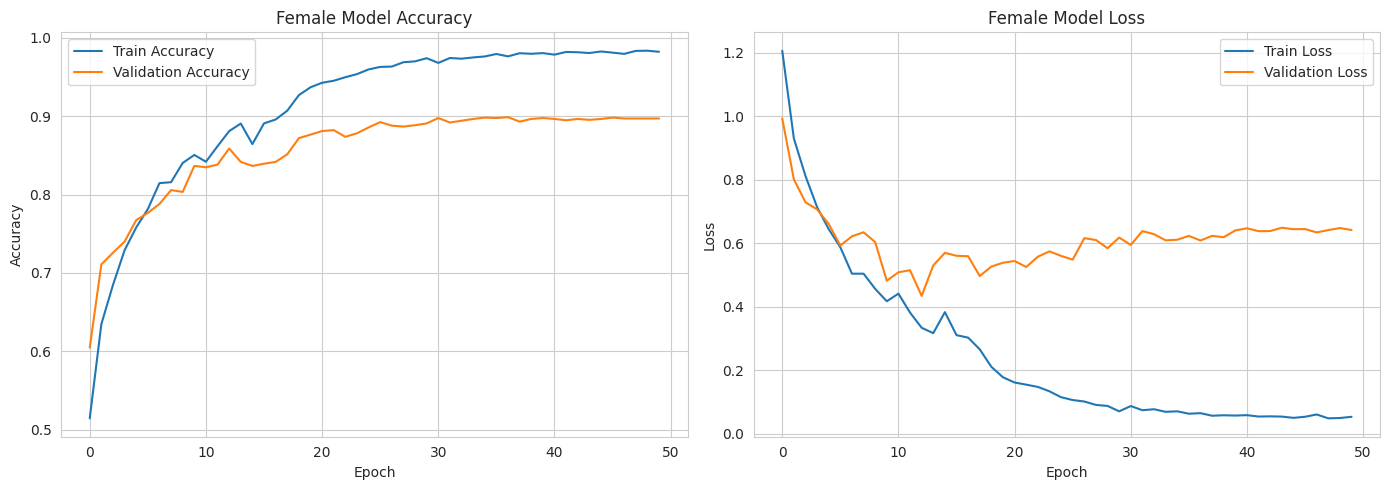

History female tersimpan.


In [12]:
print(f'\nEvaluasi model {GENDER} pada data test:')
test_loss_f, test_acc_f = model_female.evaluate(X_test_f, y_test_f, verbose=0)
print(f'  Test Loss    : {test_loss_f:.4f}')
print(f'  Test Accuracy: {test_acc_f:.4f}')

model_female.save(f'final_{GENDER}_model.keras')
print(f"Model {GENDER} disimpan sebagai 'final_{GENDER}_model.keras'")

# ── Plot training history ──────────────────────────────────────────────────
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history_female.history['accuracy'],     label='Train Accuracy')
plt.plot(history_female.history['val_accuracy'], label='Validation Accuracy')
plt.title(f'{GENDER.capitalize()} Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_female.history['loss'],     label='Train Loss')
plt.plot(history_female.history['val_loss'], label='Validation Loss')
plt.title(f'{GENDER.capitalize()} Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.savefig(f'{GENDER}_training_history.png')
print(f"Grafik training disimpan sebagai '{GENDER}_training_history.png'")
plt.show()

np.save(f'{GENDER}_training_history.npy', history_female.history)
print(f'History {GENDER} tersimpan.')

---
## 4. Ringkasan Hasil

In [13]:
print('\n' + '='*50)
print('HASIL PELATIHAN')
print('='*50)
print(f'  Male   — Test Loss: {test_loss_m:.4f} | Test Accuracy: {test_acc_m:.4f}')
print(f'  Female — Test Loss: {test_loss_f:.4f} | Test Accuracy: {test_acc_f:.4f}')
print()
print('File yang tersimpan:')
print('  best_male_model.keras, final_male_model.keras, male_training_history.npy')
print('  best_female_model.keras, final_female_model.keras, female_training_history.npy')


HASIL PELATIHAN
  Male   — Test Loss: 1.2631 | Test Accuracy: 0.7967
  Female — Test Loss: 0.6825 | Test Accuracy: 0.8959

File yang tersimpan:
  best_male_model.keras, final_male_model.keras, male_training_history.npy
  best_female_model.keras, final_female_model.keras, female_training_history.npy
